In [5]:
%pip install plotly


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import plotly.express as px
from pathlib import Path

root = Path.cwd()
if not (root / "data" / "processed").exists():
    root = root.parent
data = root / "data"

combined = pd.read_csv(data / "processed" / "sf_muni_census_combined.csv",
                       dtype={"from_stop_id": "string", "to_stop_id": "string"})
stops = pd.read_csv(data / "march_2025_gtfs" / "stops.txt",
                    usecols=["stop_id", "stop_name", "stop_lat", "stop_lon"],
                    dtype={"stop_id": "string"})

In [7]:
combined["weight_delay"] = combined["mean_delay"] * combined["observations"]

stop = (combined.groupby(["from_stop_id", "period"])
        .agg(w=("weight", "sum"), n=("observations", "sum"),
             income=("avg_median_income", "first"),
             pct_no_car=("pct_without_vehicle", "first"))
        .reset_index())
stop["mean_delay_min"] = stop["w"] / stop["n"]

stop = stop.merge(stops, left_on="from_stop_id", right_on="stop_id", how="left")
print(stop.shape, stop["stop_lat"].isna().sum())   # second number should be 0
print(stop["mean_delay_min"].describe())

KeyError: "Label(s) ['weight'] do not exist"

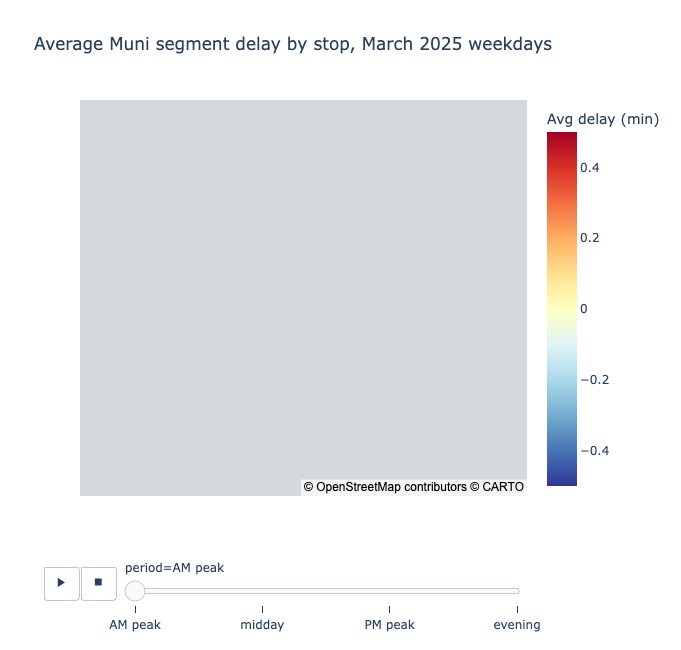

In [6]:
order = ["AM peak", "midday", "PM peak", "evening"]

fig = px.scatter_map(
    stop, lat="stop_lat", lon="stop_lon",
    color="mean_delay_min", animation_frame="period",
    category_orders={"period": order},
    color_continuous_scale="RdYlBu_r", range_color=[-0.5, 0.5],
    hover_name="stop_name",
    hover_data={"mean_delay_min": ":.2f", "income": ":,.0f", "pct_no_car": ":.1f",
                "stop_lat": False, "stop_lon": False},
    zoom=11.3, map_style="carto-positron", height=650,
    labels= {"mean_delay_min": "Avg delay (min)", "income": "Median income", "pct_no_car": "% no car"},
    title="Average Muni segment delay by stop, March 2025 weekdays",
)

# updated to center in sf
fig.update_layout(
    map_style="open-street-map",
    map_center={
        "lat": 37.77,
        "lon": -122.43
    },
    map_zoom=11.3,
    height=650
)

fig.show()
fig.write_html(root / "outputs" / "maps" / "stop_delay_by_period.html")
fig

Using FIPS code '06' for input 'CA'


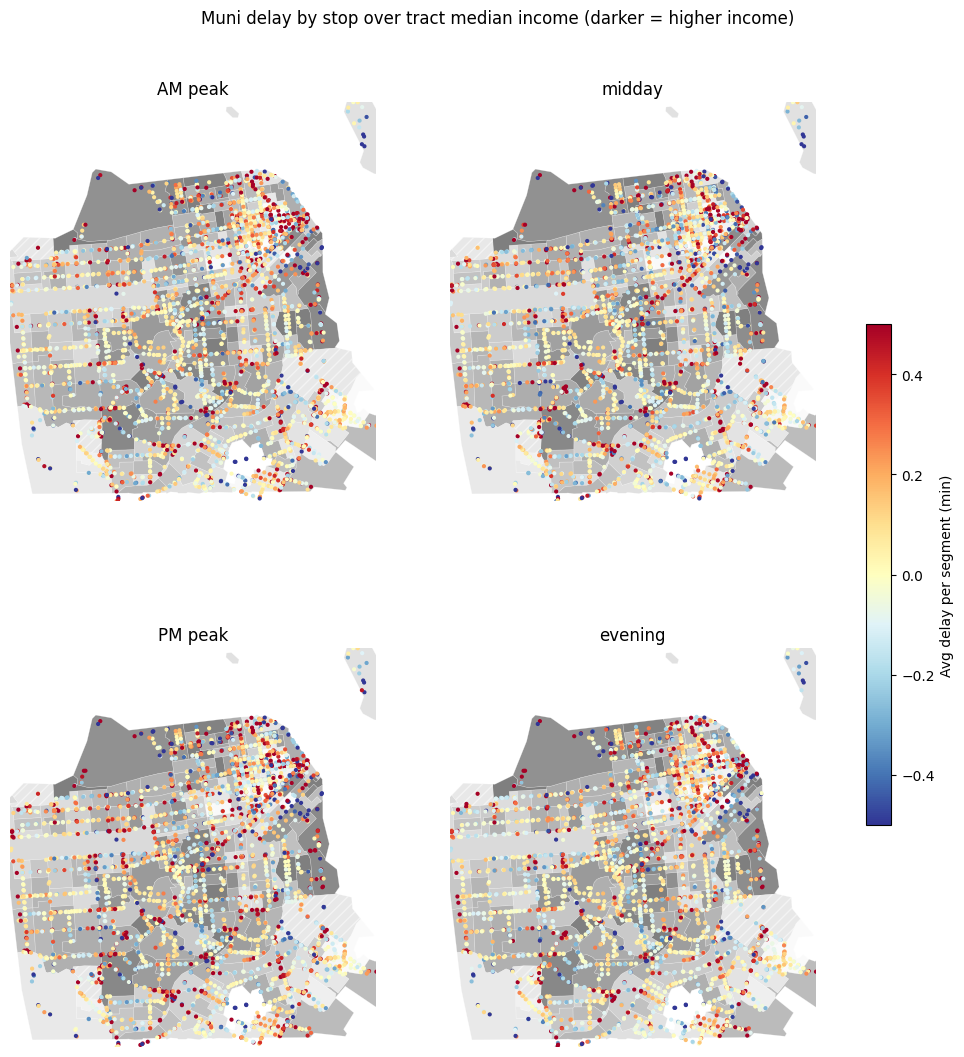

In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pygris

acs = pd.read_csv(data / "processed" / "sf_census_tracts.csv", dtype={"GEOID": "string"})
tr = pygris.tracts(state="CA", county="075", year=2024, cb=True)[["GEOID", "geometry"]]
tr = tr.merge(acs, on="GEOID").to_crs(32610)

pts = gpd.GeoDataFrame(
    stop, geometry=gpd.points_from_xy(stop["stop_lon"], stop["stop_lat"]), crs=4326
).to_crs(32610)
xmin, ymin, xmax, ymax = pts.total_bounds   # zoom to stop extent so the Farallon tract doesn't shrink the map

fig, axes = plt.subplots(2, 2, figsize=(13, 13))
for ax, p in zip(axes.flat, order):
    tr.plot(ax=ax, column="median_household_income", cmap="Greys",alpha =0.5,
            edgecolor="white", linewidth=0.3,
            missing_kwds={"color": "lightgrey", "hatch": "///"})
    pts[pts["period"] == p].plot(ax=ax, column="mean_delay_min", cmap="RdYlBu_r",
                                 vmin=-0.5, vmax=0.5, markersize=4)
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_title(p); ax.set_axis_off()

sm = plt.cm.ScalarMappable(cmap="RdYlBu_r", norm=plt.Normalize(-0.5, 0.5))
fig.colorbar(sm, ax=axes, shrink=0.5, label="Avg delay per segment (min)")
fig.suptitle("Muni delay by stop over tract median income (darker = higher income)",y=0.93)
plt.savefig(root / "outputs" / "figures" / "delay_by_period_tracts.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# Spatial join: attach the income of the track each stop falls in
stop_tract = gpd.sjoin(
    pts,
    tr[["GEOID", "median_household_income", "geometry"]],
    how="left",
    predicate="within",
)

print("before:", len(pts), "after:", len(stop_tract))
print("stops with no tract:", stop_tract["GEOID"].isna().sum())
#compare buffer weighted income with own tract income
print(stop_tract[["income", "median_household_income"]].corr().round(2))

before: 12655 after: 12655
stops with no tract: 74
                         income  median_household_income
income                     1.00                     0.87
median_household_income    0.87                     1.00


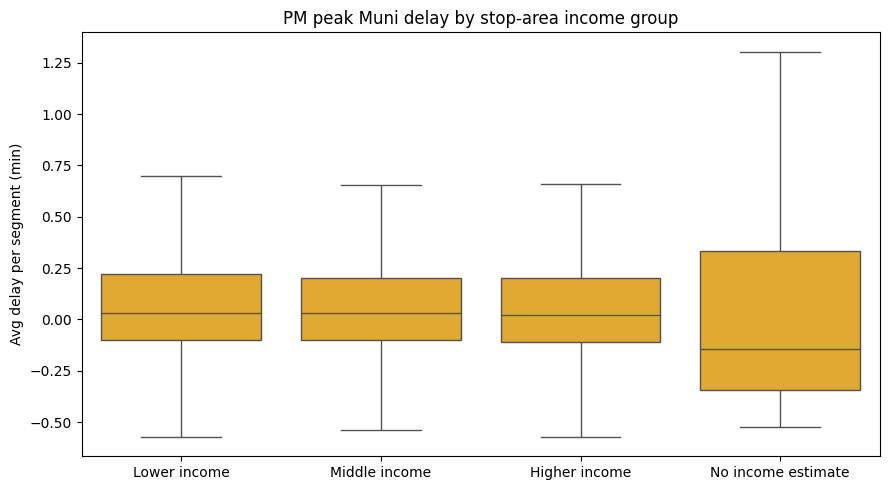

                    count  mean  median
income_group                           
Lower income         1057  0.12    0.03
Middle income        1057  0.12    0.03
Higher income        1057  0.07    0.02
No income estimate      8  0.06   -0.15


In [12]:
import seaborn as sns

pm = stop[stop["period"] == "PM peak"].copy()
pm["income_group"] = pd.qcut(pm["income"], 3,
                             labels=["Lower income", "Middle income", "Higher income"]).astype("object")
pm["income_group"] = pm["income_group"].fillna("No income estimate")
group_order = ["Lower income", "Middle income", "Higher income", "No income estimate"]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=pm, x="income_group", y="mean_delay_min", order=group_order,
            color="#FDB515", showfliers=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Avg delay per segment (min)")
ax.set_title("PM peak Muni delay by stop-area income group")
plt.tight_layout()
plt.savefig(root / "outputs" / "figures" / "pm_delay_boxplot.png", dpi=200)
plt.show()

print(pm.groupby("income_group")["mean_delay_min"]
        .agg(["count", "mean", "median"]).reindex(group_order).round(2))